# SE4095 Assignment 03 — Walkthrough Notebook
**Learning to Seed an Awareness Message with REINFORCE**

| | |
|---|---|
| **Student** | M. Waqas Chohan |
| **Roll number** | 23F-3041 |
| **Course** | SE4095 Social Network Theory and Practice |

This notebook walks through the submission step by step. It uses the same modules as `main.py`
(`environment.py`, `models.py`, `reinforce.py`, `analysis.py`), so nothing here is a separate
implementation. Run `python main.py --output results` first to produce the result files that
Sections 6–7 load.

## 1. Setup

In [1]:
import json, math, time
import numpy as np, pandas as pd, networkx as nx, torch
from IPython.display import Image, display

from environment import load_workplace_graph, IndependentCascadeSimulator, SeedSelectionEnv, FEATURE_NAMES
from models import build_policy, action_distribution, greedy_action
from reinforce import train_reinforce
import analysis

torch.set_num_threads(1)
pd.set_option("display.precision", 4)
print("torch", torch.__version__, "| numpy", np.__version__, "| networkx", nx.__version__)

torch 2.15.0+cu132 | numpy 2.5.3 | networkx 3.7


## 2. Dataset and network analysis
Load every node first, then the edges, exactly as `data/dataset_README.md` instructs.

In [2]:
wg = load_workplace_graph("data")
G = wg.graph
dept = dict(zip(wg.departments.node_id, wg.departments.department))
stats = analysis.network_statistics(G)
pd.Series(stats, name="value").to_frame()

,value
participants,92.0000
edges,755.0000
density,0.1804
connected_components,1.0000
largest_component_size,92.0000
isolated_participants,0.0000
degree_min,4.0000
degree_max,44.0000
degree_mean,16.4130
degree_median,15.5000


In [3]:
table = analysis.node_table(G, wg.nodes, wg.departments)
analysis.top_degree_table(table)

,rank,node_id,original_id,department,degree,degree_centrality,clustering_coefficient
84,1,84,804,DMCT,44,0.4835,0.2558
58,2,58,311,DSE,38,0.4176,0.2831
14,3,14,95,DSE,32,0.3516,0.3427
12,4,12,80,DMCT,31,0.3407,0.3054
27,5,27,134,DMCT,30,0.3297,0.2897
9,6,9,63,SRH,28,0.3077,0.2513
45,7,45,223,DSE,28,0.3077,0.3360
24,8,24,123,DSE,26,0.2857,0.2708
72,9,72,662,DSE,26,0.2857,0.4031
86,10,86,826,DISQ,26,0.2857,0.3231


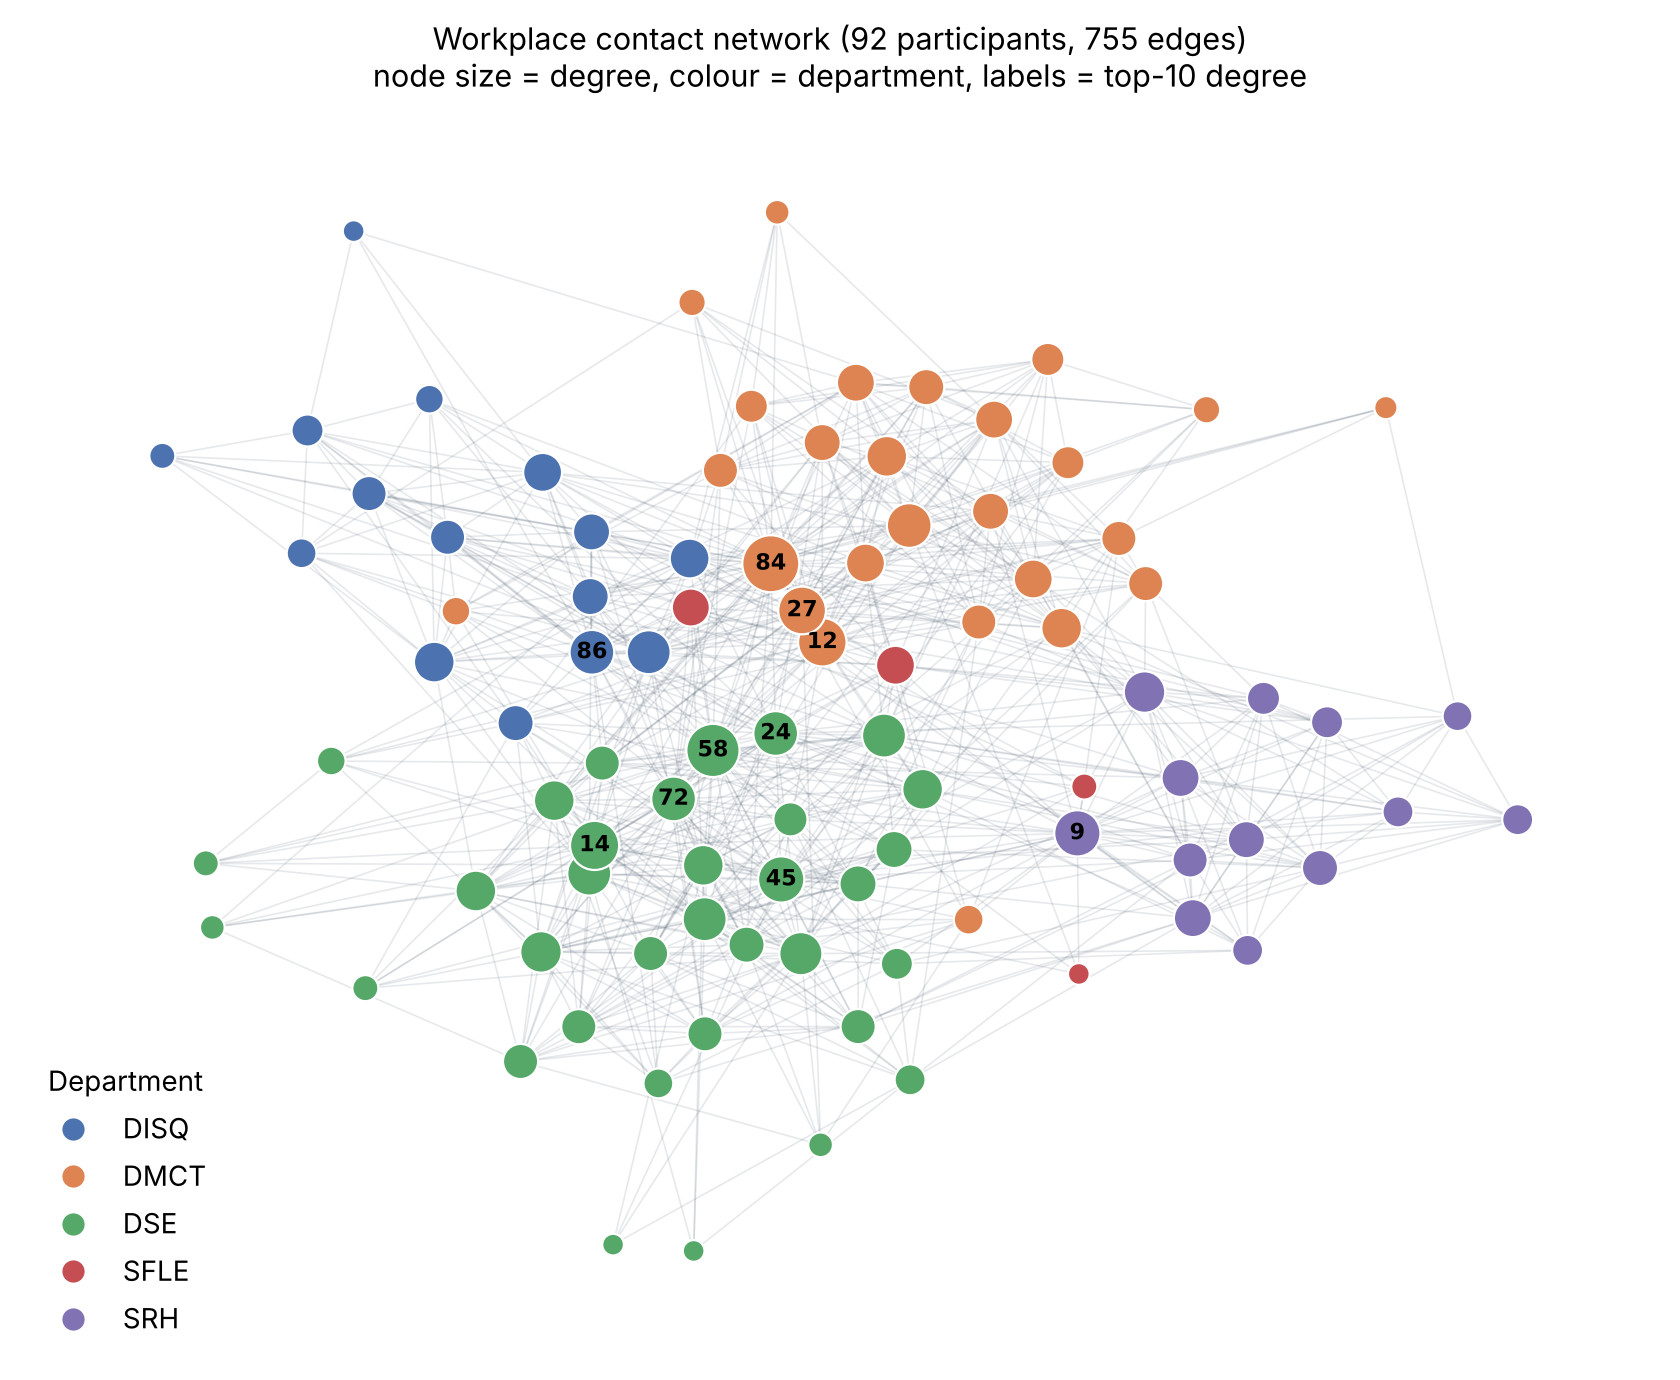

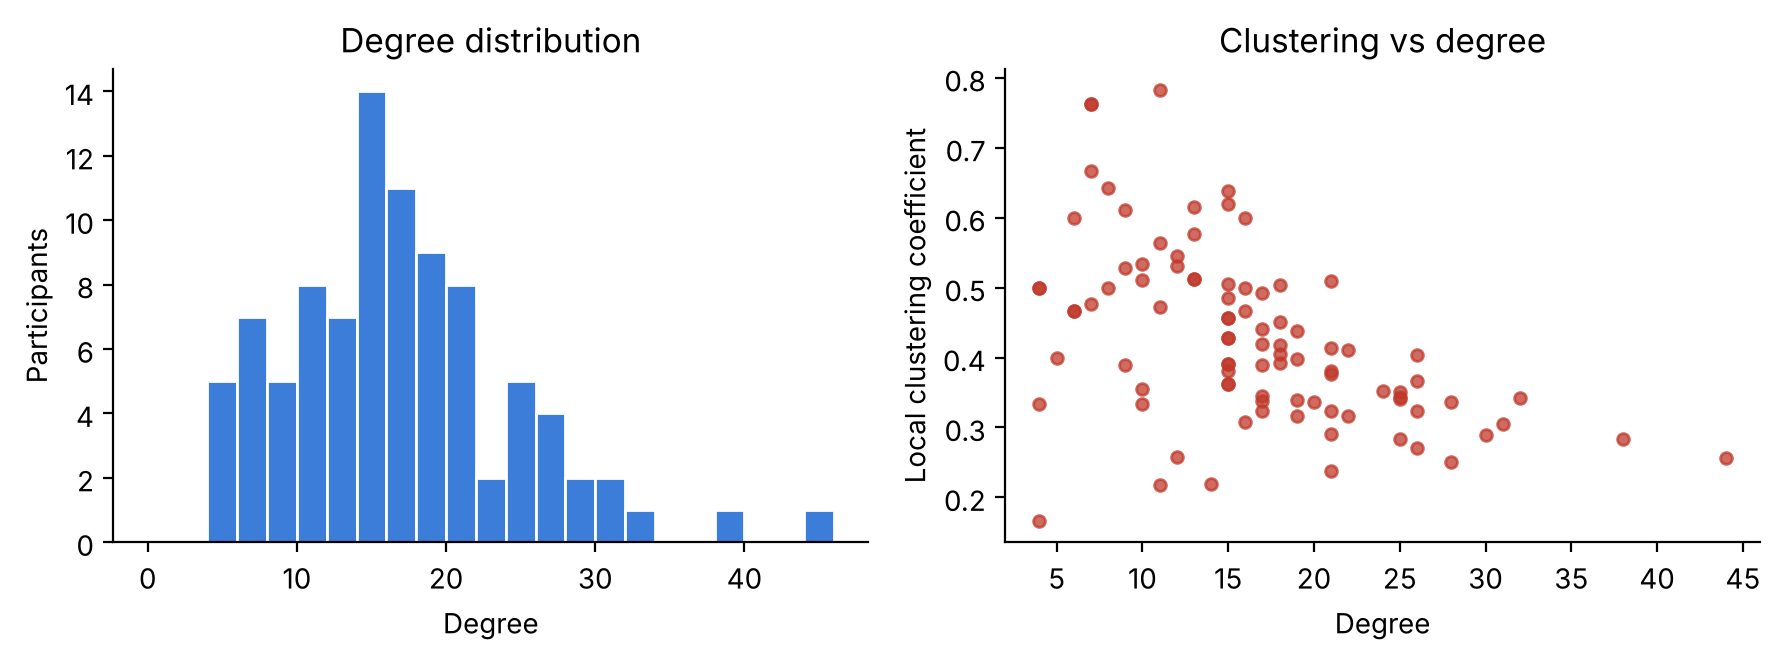

In [4]:
display(Image("results/figures/network_departments.png", width=650))
display(Image("results/figures/degree_clustering.png", width=650))

## 3. Independent Cascade simulator
Each undirected edge becomes two directed arcs, sorted by (source, target). The simulator draws one
uniform number per arc from `default_rng(diffusion_seed)`. An arc is live when its draw is below 0.10,
and the spread is the number of nodes reachable from the seeds through live arcs.

In [5]:
sim = IndependentCascadeSimulator(G, 0.10)
print("directed arcs:", sim.num_arcs, "(= 2 x", G.number_of_edges(), "edges)")
seeds = [84, 58, 14, 12, 27]
print("spread, diffusion seed 900000:", sim.spread(seeds, 900000))
print("same call again (deterministic):", sim.spread(seeds, 900000))
print("empty seed set:", sim.spread([], 1))
print("p = 0, seeds [3,3,64]:", IndependentCascadeSimulator(G, 0.0).spread([3, 3, 64], 1), "(distinct seeds only)")
print("p = 1, any seed:", IndependentCascadeSimulator(G, 1.0).spread([0], 1), "(whole connected graph)")

directed arcs: 1510 (= 2 x 755 edges)
spread, diffusion seed 900000: 62
same call again (deterministic): 62
empty seed set: 0
p = 0, seeds [3,3,64]: 2 (distinct seeds only)
p = 1, any seed: 92 (whole connected graph)


Why is the spread usually around 60? The expected number of live out-arcs per node is about
0.10 × 16.4 ≈ 1.6 > 1, so the live graph is **supercritical** and usually contains one giant component.
The distribution of spread from a single random seed shows this:

In [6]:
rng = np.random.default_rng(0)
single = [sim.spread([int(rng.integers(92))], 500000 + k) for k in range(400)]
print("single-seed spread: mean %.1f, median %.0f, share >= 40: %.2f" %
      (np.mean(single), np.median(single), np.mean(np.array(single) >= 40)))

single-seed spread: mean 38.4, median 55, share >= 40: 0.60


## 4. The RL environment
`reset(diffusion_seed)` returns an **N × 5 observation** and a **Boolean action mask**. Rewards are 0
for the first four actions, and `final_spread / N` after the fifth.

In [7]:
env = SeedSelectionEnv(G)
obs, mask = env.reset(900000)
print("observation shape:", obs.shape, "| available actions:", mask.sum())
pd.DataFrame(obs[[84, 58, 0]], columns=FEATURE_NAMES, index=["node 84", "node 58", "node 0"])

observation shape: (92, 5) | available actions: 92


,degree_centrality,clustering_coefficient,selected_indicator,selected_neighbor_fraction,remaining_budget_fraction
node 84,0.4835,0.2558,0.0,0.0,1.0
node 58,0.4176,0.2831,0.0,0.0,1.0
node 0,0.0769,0.7619,0.0,0.0,1.0


In [8]:
for a in [84, 58, 14, 12, 27]:
    obs, mask, r, done, info = env.step(a)
    print(f"action {a:>2} -> reward {r:.4f}, done {done}, remaining budget feature {obs[0, 4]:.1f}, "
          f"node 0 selected-neighbour fraction {obs[0, 3]:.3f}")
print(info)

action 84 -> reward 0.0000, done False, remaining budget feature 0.8, node 0 selected-neighbour fraction 0.000
action 58 -> reward 0.0000, done False, remaining budget feature 0.6, node 0 selected-neighbour fraction 0.000
action 14 -> reward 0.0000, done False, remaining budget feature 0.4, node 0 selected-neighbour fraction 0.143
action 12 -> reward 0.0000, done False, remaining budget feature 0.2, node 0 selected-neighbour fraction 0.143
action 27 -> reward 0.6739, done True, remaining budget feature 0.0, node 0 selected-neighbour fraction 0.143
{'final_spread': 62, 'selected_nodes': [84, 58, 14, 12, 27], 'diffusion_seconds': 0.0001476580000598915}


In [9]:
env.reset(1); env.step(4)
try:
    env.step(4)
except ValueError as e:
    print("duplicate action rejected ->", e)

duplicate action rejected -> action 4 was already selected (duplicate action)


## 5. Policies and the masked softmax
Both policies output one logit per participant. Selected participants are set to −∞ only at the
final action-selection stage, so their probability is exactly 0.

In [10]:
for arch in ["mlp", "transformer"]:
    torch.manual_seed(0)
    p = build_policy(arch)
    print(arch, "| parameters:", sum(t.numel() for t in p.parameters()), "|", p.config())
print(build_policy("transformer"))

mlp | parameters: 4609 | {'architecture': 'mlp', 'input_features': 5, 'layers': 'Linear(5,64)-ReLU-Linear(64,64)-ReLU-Linear(64,1)'}
transformer | parameters: 33921 | {'architecture': 'transformer', 'input_features': 5, 'd_model': 64, 'nhead': 4, 'num_layers': 1, 'dim_feedforward': 128, 'activation': 'relu', 'dropout': 0.0, 'norm_first': False}
TransformerPolicy(
  (input_projection): Linear(in_features=5, out_features=64, bias=True)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, e

In [11]:
torch.manual_seed(0)
policy = build_policy("transformer")
obs, mask = env.reset(5)
for a in (2, 9, 60):
    obs, mask, *_ = env.step(a)
with torch.no_grad():
    probs = action_distribution(policy, torch.from_numpy(obs), torch.from_numpy(mask)).probs
print("probabilities of selected nodes 2, 9, 60:", probs[[2, 9, 60]].tolist())
print("sum of probabilities:", float(probs.sum()))

probabilities of selected nodes 2, 9, 60: [0.0, 0.0, 0.0]
sum of probabilities: 1.0


## 6. REINFORCE training (reproducibility check)
This re-trains **MLP, seed 7** with the exact protocol (1,000 episodes, 50 updates) and confirms the
per-episode spreads match the submitted `results/training.csv`.

In [12]:
t0 = time.perf_counter()
pol, records, secs, diag = train_reinforce(SeedSelectionEnv(G), "mlp", 7, log=lambda *a: None)
print(f"trained in {secs:.1f} s, updates = {diag['num_updates']}, all finite = {diag['all_finite']}")
saved = pd.read_csv("results/training.csv").query("method == 'reinforce_mlp' and train_seed == 7")
print("identical to results/training.csv:",
      np.array_equal(saved.final_spread.to_numpy(), [r["final_spread"] for r in records]))

trained in 2.2 s, updates = 50, all finite = True
identical to results/training.csv: True


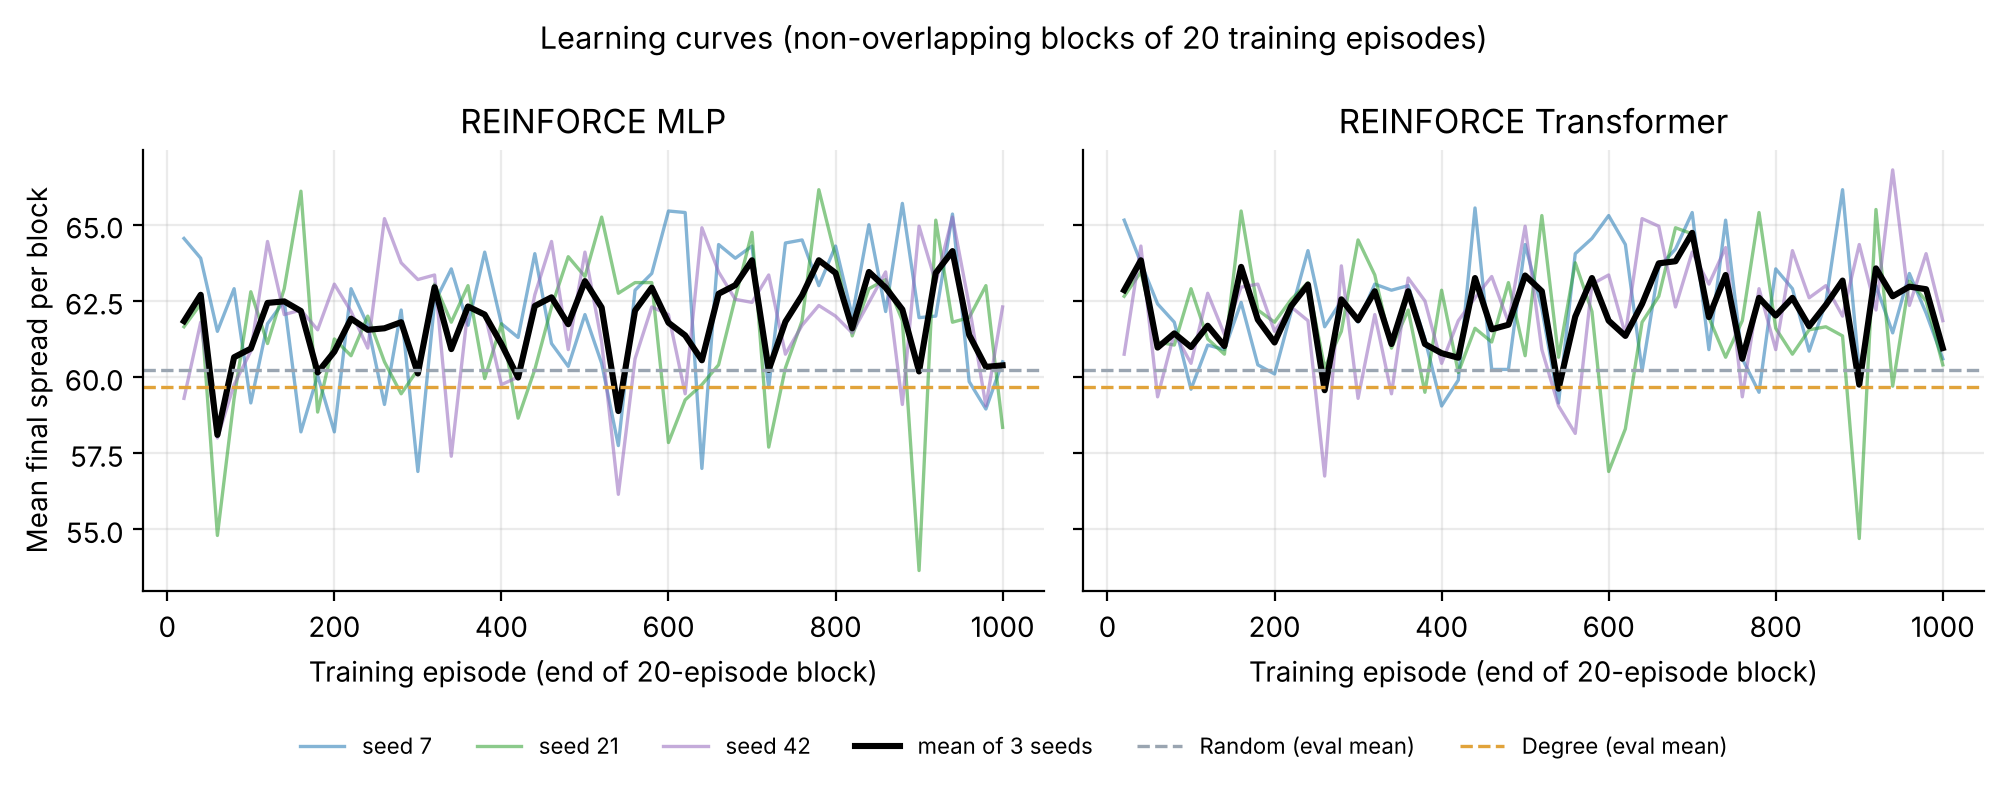

In [13]:
display(Image("results/figures/learning_curves.png", width=850))

## 7. Controlled evaluation results

In [14]:
summary = pd.read_csv("results/summary.csv")
summary

,method,train_seed,spread_mean,spread_std,reward_mean,selection_seconds_mean,training_seconds
0,random,-1,60.24,9.7161,0.6548,7.1013e-05,0.0000
1,degree,-1,59.67,7.2637,0.6486,6.4208e-05,0.0000
2,reinforce_mlp,7,58.88,13.7173,0.6400,4.8859e-04,2.3160
3,reinforce_mlp,21,58.09,16.1115,0.6314,7.1020e-04,1.9403
4,reinforce_mlp,42,55.62,18.3662,0.6046,5.6079e-04,1.9200
5,reinforce_transformer,7,58.09,16.1115,0.6314,1.6191e-03,7.8730
6,reinforce_transformer,21,59.67,7.2637,0.6486,1.6261e-03,9.6626
7,reinforce_transformer,42,58.81,14.7368,0.6392,1.6138e-03,7.8258


In [15]:
pd.read_csv("results/architecture_summary.csv")

,method,runs,mean_of_run_spread_means,population_std_of_run_spread_means,mean_training_seconds
0,reinforce_mlp,3,57.5300,1.3885,2.0588
1,reinforce_transformer,3,58.8567,0.6459,8.4538


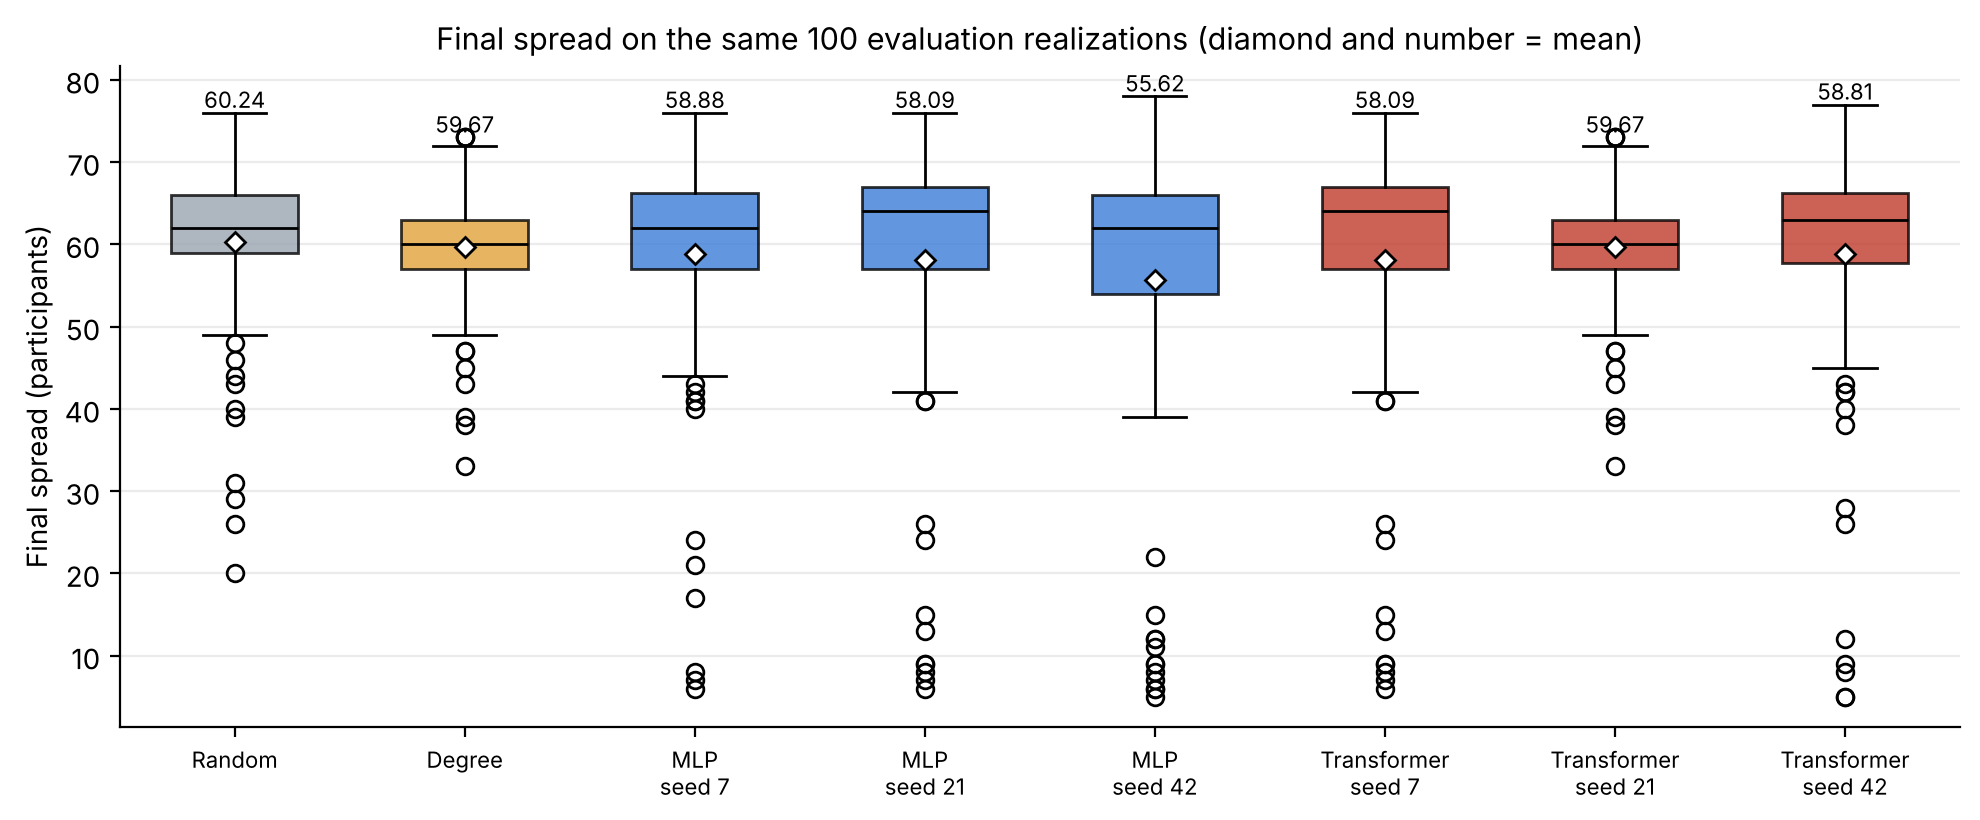

In [16]:
display(Image("results/figures/final_spread_comparison.png", width=850))

In [17]:
pd.read_csv("results/selected_users.csv")

,method,train_seed,selected_nodes,departments,department_coverage,distinct_selections_over_100
0,degree,-1,"[84, 58, 14, 12, 27]","[""DMCT"", ""DSE"", ""DSE"", ""DMCT"", ""DMCT""]",2.00,1
1,reinforce_mlp,7,"[66, 0, 36, 82, 85]","[""SRH"", ""DSE"", ""DISQ"", ""DSE"", ""DSE""]",3.00,1
2,reinforce_mlp,21,"[0, 36, 66, 82, 10]","[""DSE"", ""DISQ"", ""SRH"", ""DSE"", ""DMCT""]",4.00,1
3,reinforce_mlp,42,"[13, 71, 26, 89, 17]","[""SFLE"", ""DSE"", ""DSE"", ""DMCT"", ""DMCT""]",3.00,1
4,reinforce_transformer,7,"[66, 0, 36, 82, 10]","[""SRH"", ""DSE"", ""DISQ"", ""DSE"", ""DMCT""]",4.00,1
5,reinforce_transformer,21,"[84, 58, 14, 12, 27]","[""DMCT"", ""DSE"", ""DSE"", ""DMCT"", ""DMCT""]",2.00,1
6,reinforce_transformer,42,"[0, 36, 66, 82, 64]","[""DSE"", ""DISQ"", ""SRH"", ""DSE"", ""DSE""]",3.00,1
7,random,-1,varies per episode,varies,3.09,100


In [18]:
pd.read_csv("results/seed_neighbourhood_overlap.csv")

,method,train_seed,sum_of_degrees,closed_neighbourhood_union,edges_among_seeds
0,degree,-1,175,75,8
1,reinforce_mlp,7,47,44,0
2,reinforce_mlp,21,40,43,0
3,reinforce_mlp,42,44,36,1
4,reinforce_transformer,7,40,43,0
5,reinforce_transformer,21,175,75,8
6,reinforce_transformer,42,41,38,1


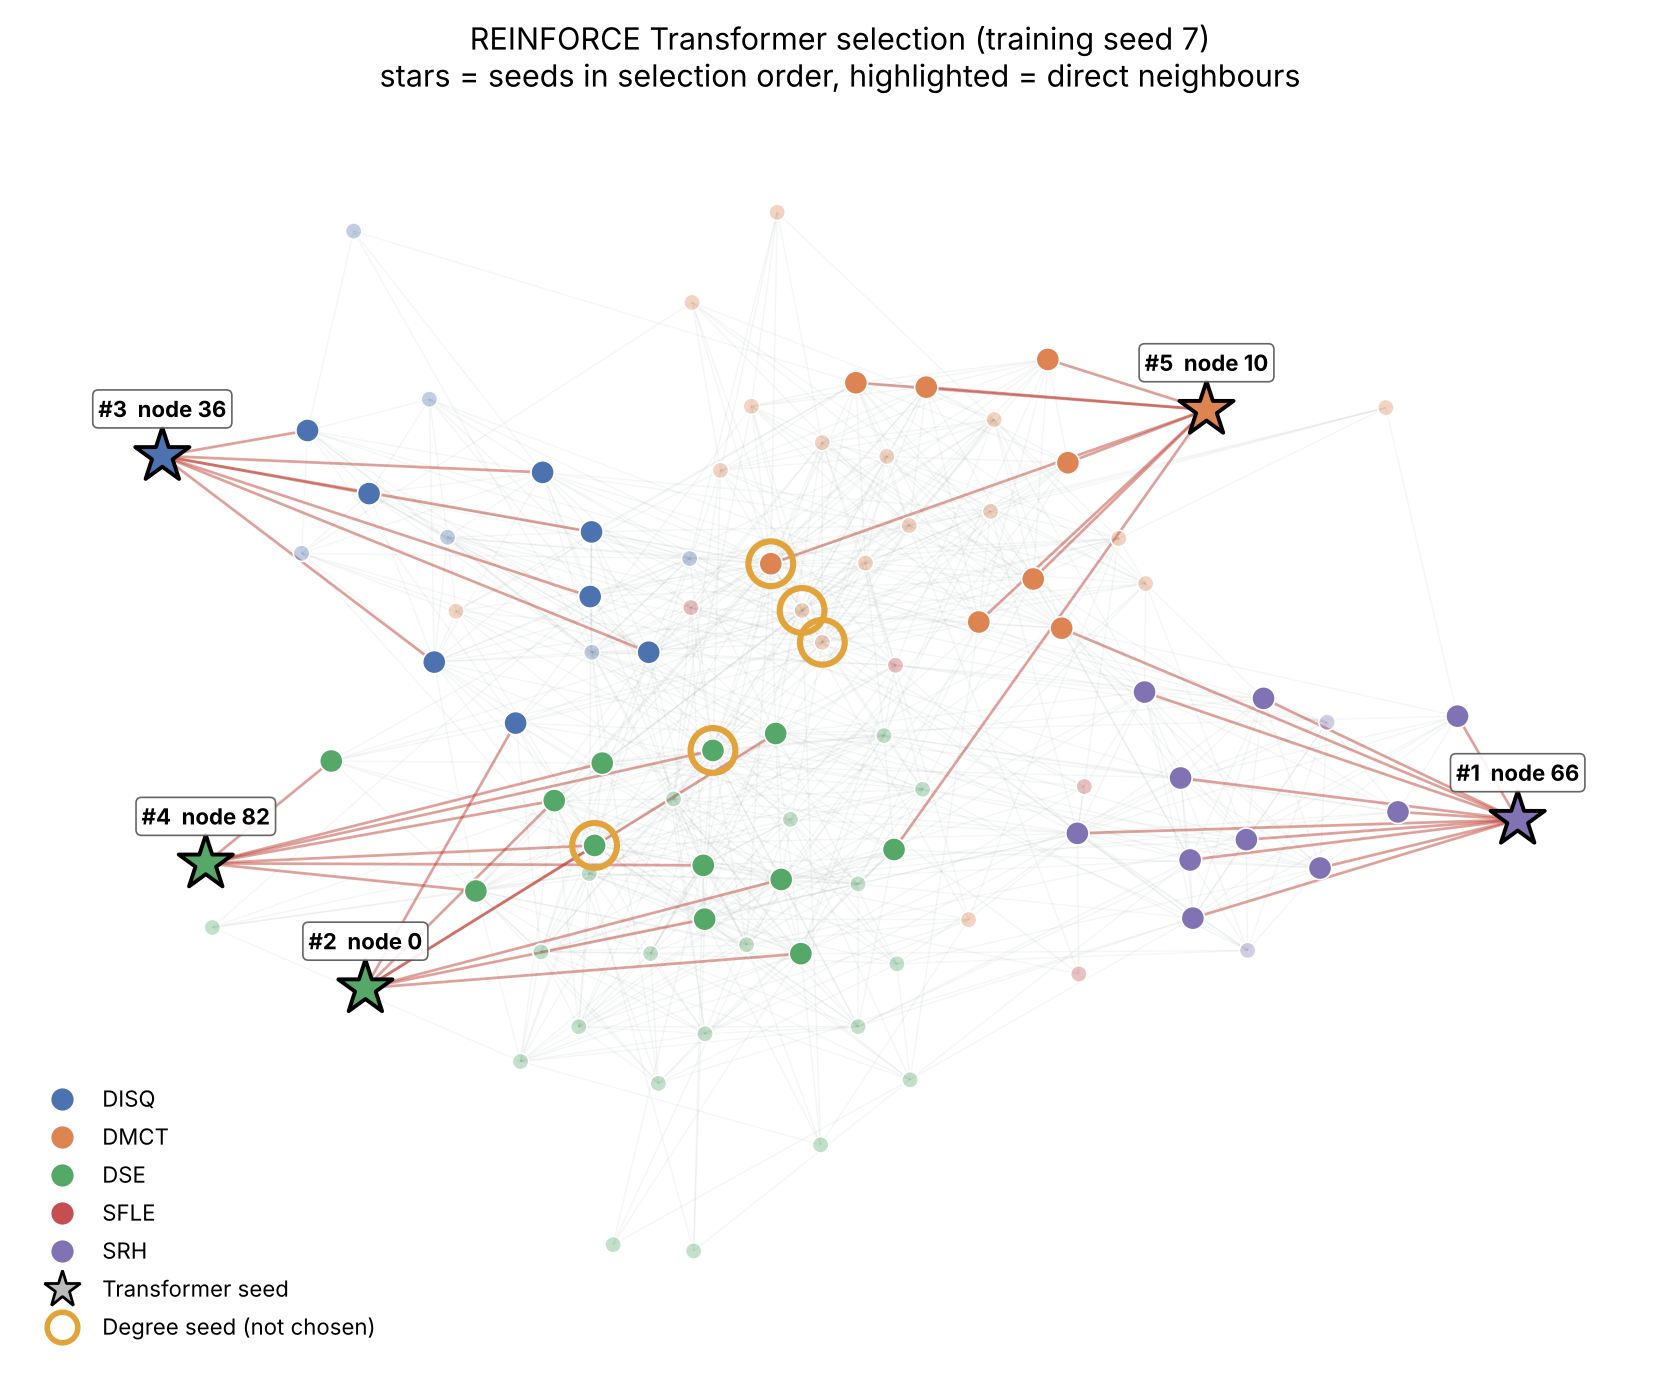

In [19]:
display(Image("results/figures/transformer_seed7_selection.png", width=650))

## 8. Why did the policies barely move?
After 50 updates the first-step distributions are still almost uniform (entropy ≈ ln 92 = 4.522), so
greedy selection mostly reflects the random initialization.

In [20]:
pd.read_csv("results/policy_diagnostics.csv")

,method,train_seed,stage,max_probability,min_probability,entropy,uniform_entropy,corr_probability_degree,top_probability_node
0,reinforce_mlp,7,initial,0.0111,0.0107,4.5218,4.5218,-0.8124,66
1,reinforce_mlp,7,final,0.0111,0.0106,4.5218,4.5218,0.0908,66
2,reinforce_mlp,21,initial,0.0111,0.0105,4.5217,4.5218,-0.9350,0
3,reinforce_mlp,21,final,0.0113,0.0104,4.5217,4.5218,-0.8296,0
4,reinforce_mlp,42,initial,0.0110,0.0108,4.5218,4.5218,0.1722,13
5,reinforce_mlp,42,final,0.0111,0.0107,4.5218,4.5218,-0.5380,13
6,reinforce_transformer,7,initial,0.0111,0.0106,4.5218,4.5218,-0.8856,0
7,reinforce_transformer,7,final,0.0140,0.0092,4.5178,4.5218,-0.5155,66
8,reinforce_transformer,21,initial,0.0119,0.0100,4.5214,4.5218,0.9176,84
9,reinforce_transformer,21,final,0.0127,0.0099,4.5208,4.5218,0.9946,84


In [21]:
checks = json.load(open("results/checks.json"))
print("all checks passed:", checks["all_passed"])
pd.Series(checks["checks"], name="result").to_frame()

all checks passed: True


,result
diffusion_empty_seed_set_zero_spread,pass
diffusion_probability_0_only_distinct_seeds,pass
diffusion_probability_1_all_reachable_active,pass
diffusion_same_inputs_same_spread,pass
diffusion_two_arcs_per_undirected_edge,pass
env_observation_shape_and_mask,pass
env_duplicate_action_rejected,pass
env_out_of_range_action_rejected,pass
env_step_after_termination_rejected,pass
env_five_distinct_selected_users,pass


## 9. Key takeaways
- **Overlapping audiences:** the top-5 Degree seeds have a combined degree of 175 but reach only 75
  distinct users in one hop, and they are densely interconnected.
- **Supercritical cascade:** at p = 0.10 almost any seed set that touches the giant live component
  reaches about 60 users. Method differences (1–2 users) are small next to realization noise (std 7–18).
- **Learning stability:** with a terminal reward of about 0.65 and only 50 updates, REINFORCE moves the
  policies very little. Results depend mostly on the seed.
- **Cost:** about 2 s (MLP) vs about 8.5 s (Transformer) per training run on one CPU thread.
- **Scope:** all claims hold only for this aggregated contact graph and a simulated adoption model.